In [6]:
import sympy as sp
import numpy as np
from scipy import signal
from scipy.linalg import solve_continuous_lyapunov
import rclpy
from std_msgs.msg import Float32
import matplotlib.pyplot as plt 
import control as ctl
from ml import NeuralNetwork

In [16]:
def sympy_to_control(expr, var):
    expr_cancel = sp.cancel(expr)
    num, den = sp.fraction(expr_cancel)
    n_coeff = [float(v) for v in sp.Poly(num, var).all_coeffs()]
    d_coeff = [float(v) for v in sp.Poly(den, var).all_coeffs()]
    return ctl.TransferFunction(n_coeff, d_coeff)


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


        c⋅(ki + s⋅(kd⋅s + kp))        
──────────────────────────────────────
c⋅(ki + s⋅(kd⋅s + kp)) + s⋅(R⋅c⋅s + 1)


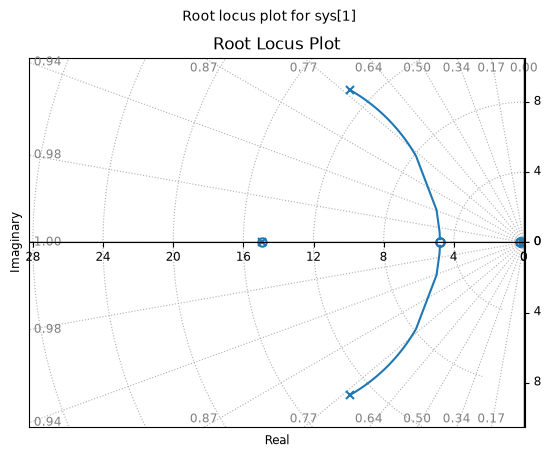

In [17]:
tau1 , tau2,  = sp.symbols('tau1 tau2 ')
k1 = sp.symbols('k')

kp_s, ki_s, kd_s, s = sp.symbols('kp ki kd s')
R, c = sp.symbols('c, R')
G = R/(1+ c*R*s)
C = kp_s + ki_s/s + kd_s*s
G_mf = (G*C)/(1+C*G)
H_mf = (G * C *G_mf)/(1 +G * C *G_mf)
sp.pprint(sp.simplify(G_mf))
result = sp.lambdify((kp_s, ki_s, kd_s, R, c, s), H_mf, modules='numpy')
# 3. Criando o array de 's'
s_vals = np.linspace(0.001, 10, 100) # Evitamos 0 exato se houver divisão por zero por causa do 'ki_s/s'
# Use a função chamando-a com um número ou array:
y = result(5.0, 1.0, 1.0, 0.1, 0.00, s_vals)
# Substitui os valores numéricos direto na expressão simbólica
H_num = H_mf.subs({kp_s: 5.0, ki_s: 1.0, kd_s: 1.0, R: 0.1, c: 0.0})
# 2. Função coringa para converter qualquer expressão do SymPy direto para o `control`

# 3. Converte direto sem o trabalho manual
sys = sympy_to_control(H_num, s)

# 4. Plota o Root Locus
plt.figure()
ctl.root_locus(sys)
plt.title("Root Locus Plot")
plt.show()
# print(type(result(5.0, 1.0, 1.0, 0.1, 0.002)))  # <class 'float'> (ou numpy.float64 dependendo do input)

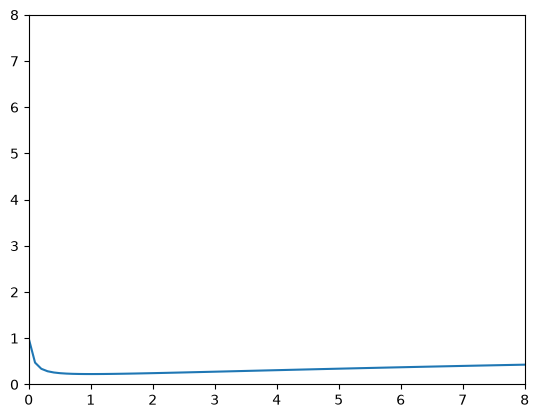

In [11]:


# 5. Plotando
fig, ax = plt.subplots()
ax.plot(s_vals, y)

ax.set(xlim=(0, 8), ylim=(0, 8))
plt.show()


In [ ]:
A = sp.Matrix([[ -1/tau1 ,   0    ],
              [  1/tau2  ,-1/tau2  ]])   
sp.pprint(A)
B_s = sp.Matrix([[k1/tau1], [0]])
C_s = sp.Matrix([[0, 1]])

# análise simbólica: autovalores exatos
print(A.eigenvals())            # {-1/tau1: 1, -1/tau2: 1}

# ganho estático simbólico: -C A^-1 B
print(sp.simplify(-C_s * A.inv() * B_s))   # K1

# passa para numpy com valores concretos
vals = (20.0, 60.0, 0.5)
A, B, C = (sp.lambdify((tau1, tau2, k1), M, 'numpy')(*vals)
           for M in (A, B_s, C_s))

t, y = signal.step(signal.StateSpace(A, B, C, np.zeros((1, 1))),
                   T=np.linspace(0, 400, 800))


⎡-1      ⎤
⎢───   0 ⎥
⎢τ₁      ⎥
⎢        ⎥
⎢1    -1 ⎥
⎢──   ───⎥
⎣τ₂   τ₂ ⎦
{-1/tau1: 1, -1/tau2: 1}
Matrix([[k]])


In [23]:

Q = np.eye(2)
# scipy resolve A X + X A^H = Q, então passamos A^T e -Q
P = solve_continuous_lyapunov(A.T, -Q)
print("P =\n", P)
print("autovalores de P:", np.linalg.eigvalsh(P))   # todos > 0 => estável
print("estável:", np.all(np.linalg.eigvalsh(P) > 0))

P =
 [[12.5  7.5]
 [ 7.5 30. ]]
autovalores de P: [ 9.72556943 32.77443057]
estável: True


In [11]:
# gera uma função: recebe números, devolve array numpy
A_func = sp.lambdify((tau1, tau2), A, modules='numpy')
A = A_func(20.0, 60.0)
print(type(A), A.dtype)   # <class 'numpy.ndarray'> float64
print(A)


<class 'numpy.ndarray'> float64
[[-0.05        0.        ]
 [ 0.01666667 -0.01666667]]


In [24]:
# pendulo invertido

M, m, l, g, b = sp.symbols('M m l g b', positive=True)

A_s = sp.Matrix([
    [0, 1,          0,                0],
    [0, -b/M,      -m*g/M,            0],
    [0, 0,          0,                1],
    [0, b/(M*l),   (M+m)*g/(M*l),     0],
])
B_s = sp.Matrix([0, 1/M, 0, -1/(M*l)])
C_s = sp.Matrix([[1, 0, 0, 0],
                 [0, 0, 1, 0]])      # mede posição e ângulo

# autovalores simbólicos (sem atrito, para ficar legível)
print(A_s.subs(b, 0).eigenvals())
# um autovalor positivo: +sqrt((M+m)g/(M l))  -> instável em malha aberta

# numérico
vals = {M: 1.0, m: 0.1, l: 0.5, g: 9.81, b: 0.1}
A = np.array(A_s.subs(vals), dtype=float)
B = np.array(B_s.subs(vals), dtype=float)
C = np.array(C_s, dtype=float)

print("polos:", np.linalg.eigvals(A))

{-sqrt(g)*sqrt(M + m)/(sqrt(M)*sqrt(l)): 1, sqrt(g)*sqrt(M + m)/(sqrt(M)*sqrt(l)): 1, 0: 2}
polos: [ 0.        +0.j -0.09090561+0.j -4.65028152+0.j  4.64118713+0.j]


In [5]:
rclpy.init()
node = rclpy.create_node('pid_test')

pub_control = node.create_publisher(Float32, '/pid/control', 10)
# pub_control2 = node.create_publisher(Float32, '/pid/control2', 10)

In [ ]:
setpoint = 100.0
setpoint2 = 101.0
dt = 0.01

In [6]:
setpoint = 100.0
pv = 0.0
kp, ki, kd = 1.0, 0.1, 0.05
previous_error = 0.0
integral = 0.0
dt = 0.1


def timer_callback():
    # pv, previous_error, integral

    # control, error, integral = pid_controller(
    # setpoint, pv, kp, ki, kd, previous_error, integral, dt)
    # pv += control * dt  # planta simplificada
    # previous_error = error
    s_vals = np.linspace(0.001, 10, 100) # Evitamos 0 exato se houver divisão por zero por causa do 'ki_s/s'
    for i in s_vals:
        # Use a função chamando-a com um número ou array:
        y = result(5.0, 1.0, 1.0, 0.1, 0.00, i)
        pub_control.publish(Float32(data=float(y)))
        # pub_control2.publish(Float32(data=float(setpoint)))
  

node.create_timer(dt, timer_callback)
try:
    rclpy.spin(node)
except KeyboardInterrupt:
    pass
finally:
    node.destroy_node()
    rclpy.shutdown()


In [ ]:


class MLP:
    def __init__(self, sizes, seed=0):
        rng = np.random.default_rng(seed)
        self.W = [rng.standard_normal((o, i)) * np.sqrt(1 / i)
                  for i, o in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros((o, 1)) for o in sizes[1:]]

    def forward(self, X):
        self.A = [X]
        for k, (W, b) in enumerate(zip(self.W, self.b)):
            Z = W @ self.A[-1] + b
            self.A.append(Z if k == len(self.W) - 1 else np.tanh(Z))  # saída linear
        return self.A[-1]

    def backward(self, y, lr=0.1):
        m = y.shape[1]
        delta = self.A[-1] - y                      # MSE + saída linear
        for i in reversed(range(len(self.W))):
            dW = delta @ self.A[i].T / m
            db = delta.sum(axis=1, keepdims=True) / m
            if i > 0:
                delta = (self.W[i].T @ delta) * (1 - self.A[i] ** 2)  # tanh'
            self.W[i] -= lr * dW
            self.b[i] -= lr * db





0 0.6920799307418608
1000 0.006113560401207008
2000 0.0018896158657016992
3000 0.0013526816801585843
4000 0.0012750374437508465
final NN: 4.99565665503779 | final PD: 4.999998849535513


In [3]:
# --- controlador "professor" (PD com saturação) ---
KP, KD, UMAX = 1.0, 2.0, 3.0
def pd(e, v):
    return np.clip(KP * e - KD * v, -UMAX, UMAX)

# --- dados: estados aleatórios -> ação do PD (normalizados) ---
rng = np.random.default_rng(1)
e = rng.uniform(-10, 10, 4000)      # erro de posição
v = rng.uniform(-5, 5, 4000)        # velocidade
X = np.vstack([e / 10, v / 5])      # (2, m)
Y = (pd(e, v) / UMAX)[None, :]      # (1, m)

net = MLP([2, 16, 16, 1])
for epoch in range(5000):
    pred = net.forward(X)
    net.backward(Y, lr=0.1)
    if epoch % 1000 == 0:
        print(epoch, np.mean((pred - Y) ** 2))

0 0.6920799307418608
1000 0.006113560401207008
2000 0.0018896158657016992
3000 0.0013526816801585843
4000 0.0012750374437508465


In [4]:
# --- malha fechada: compara NN x PD ---
def simulate(policy, target=5.0, dt=0.05, T=20.0):
    z, vz, traj = 0.0, 0.0, []
    for _ in range(int(T / dt)):
        u = policy(target - z, vz)
        vz += u * dt
        z += vz * dt
        traj.append(z)
    return np.array(traj)

nn_policy = lambda e, v: float(net.forward(np.array([[e / 10], [v / 5]]))[0, 0] * UMAX)
z_nn, z_pd = simulate(nn_policy), simulate(pd)
print("final NN:", z_nn[-1], "| final PD:", z_pd[-1])

final NN: 4.99565665503779 | final PD: 4.999998849535513


In [7]:
class ControlNetwork(NeuralNetwork):      # herda e especializa
    def __init__(self, layer_sizes):
        super().__init__(layer_sizes)
        # reinicializa com escala melhor
        for k, W in enumerate(self.weights):
            self.weights[k] = np.random.randn(*W.shape) * np.sqrt(1 / W.shape[1])

    def forward(self, X):                 # sobrescreve: tanh + saída linear
        self.activations = [X]
        A = X
        for k, (W, b) in enumerate(zip(self.weights, self.biases)):
            Z = W @ A + b
            A = Z if k == len(self.weights) - 1 else np.tanh(Z)
            self.activations.append(A)
        return A

    def backward(self, y, lr=0.1):        # sobrescreve: tanh' e MSE
        m = y.shape[1]
        delta = self.activations[-1] - y
        for i in reversed(range(len(self.weights))):
            dW = delta @ self.activations[i].T / m
            db = delta.sum(axis=1, keepdims=True) / m
            if i > 0:
                delta = (self.weights[i].T @ delta) * (1 - self.activations[i] ** 2)
            self.weights[i] -= lr * dW
            self.biases[i] -= lr * db